In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/tadpole-d1-d2/TADPOLE_D1_D2.csv


In [2]:
data = pd.read_csv("/kaggle/input/tadpole-d1-d2/TADPOLE_D1_D2.csv", low_memory=False)

data = data.query('VISCODE == "bl" and (DXCHANGE == 1 or DXCHANGE == 3)')
#data.drop(columns=['DXCHANGE'], inplace=True)
data

,RID,PTID,VISCODE,SITE,D1,D2,COLPROT,ORIGPROT,EXAMDATE,DX_bl,...,PHASE_UPENNBIOMK9_04_19_17,BATCH_UPENNBIOMK9_04_19_17,KIT_UPENNBIOMK9_04_19_17,STDS_UPENNBIOMK9_04_19_17,RUNDATE_UPENNBIOMK9_04_19_17,ABETA_UPENNBIOMK9_04_19_17,TAU_UPENNBIOMK9_04_19_17,PTAU_UPENNBIOMK9_04_19_17,COMMENT_UPENNBIOMK9_04_19_17,update_stamp_UPENNBIOMK9_04_19_17
0,2,011_S_0002,bl,11,1,1,ADNI1,ADNI1,2005-09-08,CN,...,,,,,,,,,,
1,3,011_S_0003,bl,11,1,0,ADNI1,ADNI1,2005-09-12,AD,...,ADNI1,UPENNBIOMK9,P06-MP02-MP01,P06-MP02-MP01/2,2016-12-14,741.5,239.7,22.83,NaN,2017-04-20 14:39:54.0
10,5,011_S_0005,bl,11,1,0,ADNI1,ADNI1,2005-09-07,CN,...,ADNI1,UPENNBIOMK9,P06-MP02-MP01,P06-MP02-MP01/2,2016-11-22,547.3,337,33.43,NaN,2017-04-20 14:39:54.0
20,7,022_S_0007,bl,22,1,0,ADNI1,ADNI1,2005-10-06,AD,...,,,,,,,,,,
22,8,011_S_0008,bl,11,1,1,ADNI1,ADNI1,2005-09-19,CN,...,ADNI1,UPENNBIOMK9,P06-MP02-MP01,P06-MP02-MP01/2,2017-01-06,3592,440.2,37.51,Recalculated ABETA result = 3592 pg/mL,2017-04-20 14:39:54.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10794,5275,135_S_5275,bl,135,1,1,ADNI2,ADNI2,2013-08-27,AD,...,ADNI2,UPENNBIOMK9,P06-MP02-MP01,P06-MP02-MP01/2,2016-12-20,832.7,490.4,53.18,NaN,2017-04-20 14:39:56.0
10798,5282,082_S_5282,bl,82,1,1,ADNI2,ADNI2,2013-09-09,SMC,...,ADNI2,UPENNBIOMK9,P06-MP02-MP01,P06-MP02-MP01/2,2016-12-07,558.9,170.7,15.63,NaN,2017-04-20 14:39:56.0
10800,5287,053_S_5287,bl,53,1,1,ADNI2,ADNI2,2013-09-18,SMC,...,ADNI2,UPENNBIOMK9,P06-MP02-MP01,P06-MP02-MP01/2,2017-01-18,2358,268.4,26.11,Recalculated ABETA result = 2358 pg/mL,2017-04-20 14:39:56.0
10802,5295,057_S_5295,bl,57,1,1,ADNI2,ADNI2,2013-12-11,SMC,...,ADNI2,UPENNBIOMK9,P06-MP02-MP01,P06-MP02-MP01/2,2017-01-13,416.8,88.69,8.53,NaN,2017-04-20 14:39:56.0


<b>RISK FACTORS:</b>
* REFERENCES:
1. https://www.mayoclinic.org/diseases-conditions/alzheimers-disease/symptoms-causes/syc-20350447 (MAYOCLINIC) 
2. *  https://www.physio-pedia.com/Mini-Mental_State_Examination    
   *  https://pubmed.ncbi.nlm.nih.gov/18579155/(National Library of Medicine)





<b>POSSIBLE RISK FACTORS DETERMINED BY SOURCES:</b>
1. MMSE-The MMSE test score of participant
2. APOE4-No of alleles of APOE4 gene in participant
3. AGE-AGE of participant in years
4. PTEDUCAT-No of years of formal education of participant


# PREDICTION OF THE CATEGORIES OF PEOPLE PRONE TO RISK OF ALZHEIMER'S

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

sns.set()

In [4]:
td = data[["RID","AGE", "PTEDUCAT", "APOE4", "MMSE", "DX"]]
td

,RID,AGE,PTEDUCAT,APOE4,MMSE,DX
0,2,74.3,16,0.0,28.0,NL
1,3,81.3,18,1.0,20.0,Dementia
10,5,73.7,16,0.0,29.0,NL
20,7,75.4,10,1.0,20.0,Dementia
22,8,84.5,18,0.0,28.0,NL
...,...,...,...,...,...,...
10794,5275,78.0,12,1.0,24.0,Dementia
10798,5282,66.9,17,1.0,29.0,NL
10800,5287,78.9,16,0.0,29.0,NL
10802,5295,75.5,15,1.0,29.0,NL


<b>COGNITIVE TEST SCORE-MMSE</b>

(15.0, 30.0)

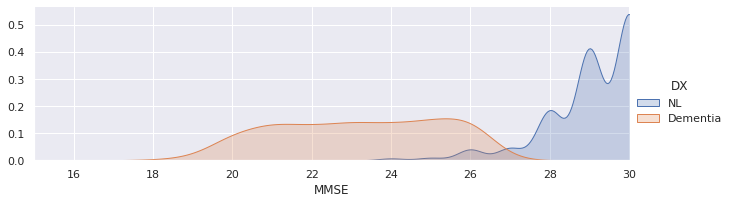

In [5]:
facet= sns.FacetGrid(td,hue="DX", aspect=3)
facet.map(sns.kdeplot,'MMSE',shade= True)
facet.set(xlim=(0, td['MMSE'].max()))
facet.add_legend()
plt.xlim(15,30)

**CONCLUSION:More people in the mmse score range of 18-26 have dementia 
More People with high MMSE score more than 27 are Normal.**

**Low MMSE Score is linked to alzheimer's**



<b>APOE4 GENE ALLELES</b>

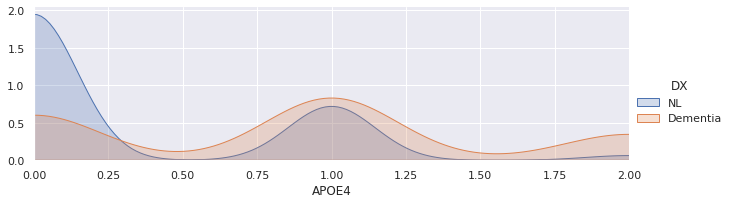

In [6]:

facet= sns.FacetGrid(td,hue="DX", aspect=3)
facet.map(sns.kdeplot,'APOE4',shade= True)
facet.set(xlim=(0, td['APOE4'].max()))
facet.add_legend()



**CONCLUSION:More people with APOE4=1&2 are demented and APOE4=0 are non demented**


<b>AGE<b>

(50.0, 100.0)

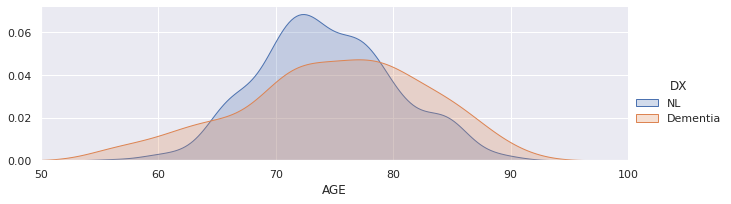

In [7]:

facet= sns.FacetGrid(td,hue="DX", aspect=3)
facet.map(sns.kdeplot,'AGE',shade= True)
facet.set(xlim=(0, td['AGE'].max()))
facet.add_legend()
#plt.xlim(0,100)
plt.xlim(50,100)

**CONCLUSION:More people in the age groups of >=80 are demented than normal**



<b>EDUCATION<b>

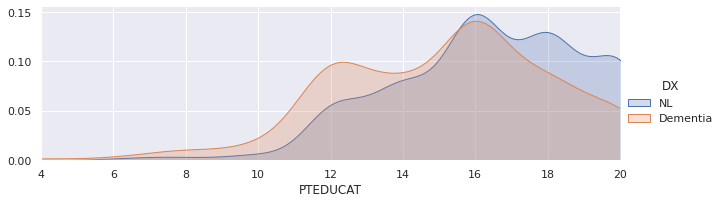

In [8]:
#'EDUC' = Years of Education
# Nondemented = 0, Demented =1
facet= sns.FacetGrid(td,hue="DX", aspect=3)
facet.map(sns.kdeplot,'PTEDUCAT',shade= True)
facet.set(xlim=(td['PTEDUCAT'].min(), td['PTEDUCAT'].max()))
facet.add_legend()


**CONCLUSION:More people with EDUC<=15 are demented more than normal.
People who don't finish high school are at a higher risk of developing dementia and Alzheimer's disease compared to people with more education, regardless of lifestyle choices and characteristics such as income, occupation, physical activity and smoking, according to a new study.**

**HENCE low level of eduation is linked to dementia**



**FINAL CONCLUSION OF RISK FACTORS FROM THE ADNI DATA:**

Therefore lifestyle,medical factors influence the disease risk

The Individuals more vulnerable to alzheimer's are:

    1.With less MMSE score
    2.Aged People
    3.With multiple copies of APOE4 allele(1&2)
    4.With less education
    
    